In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle

class AcousticSimulator:
    def __init__(self, c=340.0, omega=10.0, 
                 source_type='single', cs_radius=100.0,
                 src_init_pos=(0.0, 0.0), src_vel=(150.0, 0.0),
                 obs_init_pos=(1500.0, 500.0), obs_vel=(0.0, 0.0),
                 duration=3.5, fps=30, vector_lines=True, title=None,
                 x_bounds = (-200, 1600), y_bounds=(-600,600)):
        
        # Physics Parameters
        self.c = c
        self.omega = omega
        self.k = self.omega / self.c
        self.source_type = source_type
        
        # Dynamic Geometry
        self.cs_radius = cs_radius
        self.src_pos = np.array(src_init_pos, dtype=float)
        self.src_vel = np.array(src_vel, dtype=float)
        self.obs_pos = np.array(obs_init_pos, dtype=float)
        self.obs_vel = np.array(obs_vel, dtype=float)
        
        # Display Toggles
        self.vector_lines = vector_lines
        self.title = title
        self.x_bounds = x_bounds
        self.y_bounds = y_bounds
        
        # Animation Settings
        self.fps = fps
        self.dt = 1.0 / fps
        self.frames = int(duration * fps)
        self.emit_rate = 10  # Waves per second
        self.frames_per_emission = int(self.fps / self.emit_rate)
        
        # State tracking
        self.waves = []
        self.emission_times = []
        self.current_time = 0.0

        # Calculate Dual Source Separation (delta)
        if self.source_type == 'dual':
            self.delta = 0.01 / self.k
            # Multiply separation ONLY for visual clarity on a large plot
            self.viz_delta = self.delta * 50.0 
        else:
            self.delta = 0.0
            self.viz_delta = 0.0

        self.setup_plot()

    def setup_plot(self):
        """Initializes the Matplotlib figure and drawing objects."""
        self.fig, self.ax = plt.subplots(figsize=(12, 5))
        
        # Dynamic framing based on initial positions and velocities
        max_x = max(self.src_pos[0] + self.src_vel[0]*3, self.obs_pos[0] + self.obs_vel[0]*3) + 200
        min_x = min(self.src_pos[0], self.obs_pos[0]) - 300
        self.ax.set_xlim(self.x_bounds)
        self.ax.set_ylim(self.y_bounds)
        self.ax.set_aspect('equal')
        
        title_str = f"{self.title}\n"
        title_str += f"U_src={self.src_vel} m/s | U_obs={self.obs_vel} m/s | CS_r={self.cs_radius}m"
        self.ax.set_title(title_str, fontsize=11)
        self.ax.set_xlabel('X Position (m)')
        self.ax.set_ylabel('Y Position (m)')
        self.ax.grid(True, linestyle='--', alpha=0.5)

        # Plot Elements
        self.control_surface = Circle((0, 0), radius=self.cs_radius, fill=False, color='grey', ls='--', lw=2, zorder=2, label='Control Surface')
        self.ax.add_patch(self.control_surface)
        
        self.src_center_dot, = self.ax.plot([], [], 'ro', markersize=6, zorder=5, label='Point Source')
        
        if self.source_type == 'dual':
            self.src1_dot, = self.ax.plot([], [], 'r+', markersize=8, zorder=5, label='+ Monopole')
            self.src2_dot, = self.ax.plot([], [], 'b_', markersize=8, zorder=5, label='- Monopole')
            
        self.obs_dot, = self.ax.plot([], [], 'kX', markersize=10, zorder=5, label='Observer')
        
        # Tracking Lines (Conditionally add labels so they don't show up in legend if turned off)
        if self.vector_lines:
            self.analytical_line, = self.ax.plot([], [], 'k-', alpha=0.4, lw=1, zorder=3, label='Analytical Vector (r)')
            self.numerical_line, = self.ax.plot([], [], 'g-', lw=2, zorder=4, label='Numerical Vector (CS to Obs)')
        else:
            self.analytical_line, = self.ax.plot([], [], visible=False)
            self.numerical_line, = self.ax.plot([], [], visible=False)
            
        self.ax.legend(loc='upper right', fontsize=8)

    def init_anim(self):
        """Initializes empty data for the animation start."""
        self.src_center_dot.set_data([], [])
        self.obs_dot.set_data([], [])
        self.analytical_line.set_data([], [])
        self.numerical_line.set_data([], [])
        if self.source_type == 'dual':
            self.src1_dot.set_data([], [])
            self.src2_dot.set_data([], [])
        return self.get_artists()

    def get_artists(self):
        """Returns all changing matplotlib objects for blitting."""
        artists = [self.src_center_dot, self.obs_dot, self.control_surface, 
                   self.analytical_line, self.numerical_line] + self.waves
        if self.source_type == 'dual':
            artists.extend([self.src1_dot, self.src2_dot])
        return artists

    def animate(self, frame):
        """The core physics and update loop for each frame."""
        self.current_time = frame * self.dt
        
        # 1. Kinematics updates
        curr_src_pos = self.src_pos + self.src_vel * self.current_time
        curr_obs_pos = self.obs_pos + self.obs_vel * self.current_time
        
        # 2. Geometry updates
        self.src_center_dot.set_data([curr_src_pos[0]], [curr_src_pos[1]])
        self.obs_dot.set_data([curr_obs_pos[0]], [curr_obs_pos[1]])
        self.control_surface.center = (curr_src_pos[0], curr_src_pos[1])
        
        if self.source_type == 'dual':
            # Offset sources along X-axis using the visual delta
            self.src1_dot.set_data([curr_src_pos[0] - self.viz_delta/2], [curr_src_pos[1]])
            self.src2_dot.set_data([curr_src_pos[0] + self.viz_delta/2], [curr_src_pos[1]])

        # 3. Radiation Vector Tracking
        if self.vector_lines:
            vec_to_obs = curr_obs_pos - curr_src_pos
            dist_to_obs = np.linalg.norm(vec_to_obs)
            
            if dist_to_obs > 0:
                unit_vec = vec_to_obs / dist_to_obs
                cs_intersection = curr_src_pos + unit_vec * self.cs_radius
                
                self.analytical_line.set_data([curr_src_pos[0], curr_obs_pos[0]], [curr_src_pos[1], curr_obs_pos[1]])
                self.numerical_line.set_data([cs_intersection[0], curr_obs_pos[0]], [cs_intersection[1], curr_obs_pos[1]])
        
        # 4. Wave Emission & Propagation (with pi Phase Delay)
        if frame % self.frames_per_emission == 0:
            if self.source_type == 'single':
                self.emit_wave(curr_src_pos, color='blue', ls='solid')
            elif self.source_type == 'dual':
                # Positive monopole emits at t=0
                pos1 = curr_src_pos + np.array([-self.viz_delta/2, 0])
                self.emit_wave(pos1, color='red', ls='solid')

        # Negative monopole emits half a cycle later (pi phase shift)
        if self.source_type == 'dual' and (frame + self.frames_per_emission // 2) % self.frames_per_emission == 0:
            pos2 = curr_src_pos + np.array([self.viz_delta/2, 0])
            self.emit_wave(pos2, color='blue', ls='dotted')

        # Radiate waves
        for i, wave in enumerate(self.waves):
            r = self.c * (self.current_time - self.emission_times[i])
            wave.set_radius(r)
            alpha = max(0, 1.0 - (r / 1500.0)) 
            wave.set_alpha(alpha)
            
        return self.get_artists()

    def emit_wave(self, position, color, ls):
        circle = Circle(tuple(position), radius=0, fill=False, color=color, ls=ls, lw=1.2, alpha=1.0, zorder=1)
        self.ax.add_patch(circle)
        self.waves.append(circle)
        self.emission_times.append(self.current_time)

    def generate_gif(self, filename="fwh_simulation.gif"):
        """Compiles the animation and saves it to disk."""
        print(f"Generating {filename}...")
        anim = animation.FuncAnimation(self.fig, self.animate, init_func=self.init_anim, 
                                       frames=self.frames, interval=1000/self.fps, blit=True)
        anim.save(filename, writer='pillow', fps=self.fps)
        print("Done!")

Generating stationary_monopole.gif...
Done!


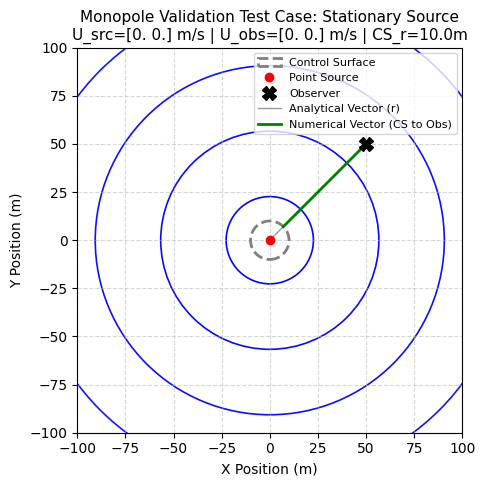

In [5]:
if __name__ == "__main__":
    sim_single_mono = AcousticSimulator(
        source_type='single',
        src_init_pos=(0.0,0.0),
        src_vel=(0.0,0.0),
        obs_init_pos=(50.0,50.0),
        obs_vel=(0.0,0.0),
        cs_radius=10.0,
        vector_lines=True,
        duration=3,
        title="Monopole Validation Test Case: Stationary Source",
        x_bounds=(-100,100),
        y_bounds=(-100,100)
    )
    sim_single_mono.generate_gif("stationary_monopole.gif")
    # sim_single = AcousticSimulator(
    #     source_type='single',
    #     src_init_pos=(0.0, 0.0),
    #     src_vel=(150.0, 0.0),
    #     obs_init_pos=(500.0, 500.0),
    #     obs_vel=(0.0, 0.0),
    #     cs_radius=400.0,
    #     vector_lines=True,
    #     duration=10,
    #     title="Dipole Validation Test Case: Plane Wave Assumption"
    # )
    # sim_single.generate_gif("single_dipole_old.gif")

    # sim_dual = AcousticSimulator(
    #     source_type='dual',
    #     src_init_pos=(0.0, 0.0),
    #     src_vel=(150.0, 0.0),
    #     obs_init_pos=(500.0, 500.0),
    #     obs_vel=(0.0, 0.0),
    #     cs_radius=400.0,
    #     vector_lines=False,
    #     duration=10,
    #     title="Dipole Validation Test Case: Dual Monopole Method"
    # )
    # sim_dual.generate_gif("dual_monopole_old.gif")